# Transformasi Geometris Citra
**Nama:** Khalil Aziz

**NIM:**  G.211.24.0096

Transformasi yang diimplementasikan (semuanya dalam bentuk *function*):
1. Translasi 2. Rotasi 3. Scaling 4. Shearing 5. Refleksi 6. Affine 7. Proyektif (Perspective)

Dataset: 20 citra dari **satu foto kuda yang sama**, masing-masing diberi kondisi berbeda (noise, kecerahan, kontras, blur, dll).  
Alur: siapkan dataset → baca 20 citra → konversi grayscale → samakan ukuran → terapkan 7 transformasi → simpan & tampilkan hasil.

## 1. Import & Konfigurasi

In [1]:
import os, glob, zipfile, urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ====== KONFIGURASI ======
FOLDER_DATASET = "/content/dataset"             # folder 20 citra kuda
FOLDER_HASIL   = "/content/hasil_transformasi"  # folder output
URL_FOTO_KUDA  = "https://raw.githubusercontent.com/pjreddie/darknet/master/data/horses.jpg"
ZIP_DATASET    = "/content/dataset_kuda_variasi.zip"   # opsional: zip dataset yang diupload manual
UKURAN_SERAGAM = (384, 256)   # (lebar, tinggi) -> semua citra diseragamkan, rasio 3:2
MIN_CITRA      = 20

## 2. Menyiapkan Dataset (20 Citra Kuda, Citra Dasar Sama)
Fungsi `siapkan_dataset()` memilih salah satu cara secara otomatis:
1. Jika `FOLDER_DATASET` sudah berisi ≥ 20 citra → dipakai apa adanya.
2. Jika ada `dataset_kuda_variasi.zip` di `/content` (hasil upload manual) → di-ekstrak.
3. Jika tidak ada → foto kuda diunduh lalu dibuat 20 variasi (noise, terang/gelap, kontras, blur, dll).

In [2]:
def buat_variasi(img, seed=42):
    """Membuat 20 variasi dari SATU citra: asli, noise, kecerahan, kontras, gamma, blur, dll."""
    rng = np.random.default_rng(seed)
    f = img.astype(np.float32)
    clip = lambda x: np.clip(x, 0, 255).astype(np.uint8)

    def gauss(sigma):
        return clip(f + rng.normal(0, sigma, f.shape))

    def garam_merica(p):
        o = img.copy(); m = rng.random(img.shape[:2])
        o[m < p / 2] = 0
        o[m > 1 - p / 2] = 255
        return o

    def gamma(g):
        return clip(255 * (f / 255) ** g)

    def blur_gerak(k):
        ker = np.zeros((k, k), np.float32); ker[k // 2, :] = 1.0 / k
        return cv2.filter2D(img, -1, ker)

    def jpeg(q):
        _, buf = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, q])
        return cv2.imdecode(buf, cv2.IMREAD_COLOR)

    def vignette():
        h, w = img.shape[:2]
        mask = cv2.getGaussianKernel(h, h / 2.2) @ cv2.getGaussianKernel(w, w / 2.2).T
        return clip(f * (mask / mask.max())[..., None])

    return [
        ("asli", img),
        ("noise_gaussian_ringan", gauss(15)),
        ("noise_gaussian_berat", gauss(35)),
        ("noise_saltpepper_ringan", garam_merica(0.02)),
        ("noise_saltpepper_berat", garam_merica(0.08)),
        ("noise_speckle", clip(f + f * rng.normal(0, 0.2, f.shape))),
        ("noise_poisson", clip(rng.poisson(f / 255 * 30) / 30 * 255)),
        ("terang_sedang", clip(f + 40)),
        ("terang_tinggi", clip(f + 90)),
        ("gelap_sedang", clip(f - 40)),
        ("gelap_tinggi", clip(f - 90)),
        ("kontras_tinggi", clip((f - 128) * 1.6 + 128)),
        ("kontras_rendah", clip((f - 128) * 0.5 + 128)),
        ("gamma_terang", gamma(0.5)),
        ("gamma_gelap", gamma(2.0)),
        ("blur_gaussian", cv2.GaussianBlur(img, (15, 15), 0)),
        ("blur_gerak", blur_gerak(21)),
        ("kompresi_jpeg_rendah", jpeg(8)),
        ("kabut", clip(f * 0.55 + 255 * 0.45)),
        ("vignette", vignette()),
    ]


def hitung_citra(folder):
    if not os.path.isdir(folder):
        return 0
    return len([n for n in os.listdir(folder)
                if n.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"))])


def siapkan_dataset(folder=FOLDER_DATASET):
    if hitung_citra(folder) >= MIN_CITRA:
        print(f"Dataset sudah ada ({hitung_citra(folder)} citra) di: {folder}")
        return
    os.makedirs(folder, exist_ok=True)

    if os.path.exists(ZIP_DATASET):                       # cara 2: zip hasil upload
        with zipfile.ZipFile(ZIP_DATASET) as z:
            for info in z.infolist():
                if not info.is_dir():
                    with open(os.path.join(folder, os.path.basename(info.filename)), "wb") as out:
                        out.write(z.read(info))
        print(f"Dataset diekstrak dari zip -> {folder}")
        return

    print("Mengunduh foto kuda ...")                      # cara 3: unduh + buat variasi
    path_foto = os.path.join(folder, "_sumber_kuda.jpg")
    urllib.request.urlretrieve(URL_FOTO_KUDA, path_foto)
    foto = cv2.imread(path_foto)
    os.remove(path_foto)
    assert foto is not None, "Foto kuda gagal dibaca"
    for i, (nama, im) in enumerate(buat_variasi(foto), 1):
        cv2.imwrite(os.path.join(folder, f"kuda_{i:02d}_{nama}.png"), im)
    print(f"20 citra variasi dibuat di: {folder}")


siapkan_dataset()

Dataset sudah ada (20 citra) di: /content/dataset


## 3. Membaca Dataset + Konversi Grayscale
Setiap citra dibaca dari folder, diubah ke **grayscale**, lalu diseragamkan ukurannya sehingga seluruh citra memiliki dimensi dan format yang sama.

In [3]:
def muat_dataset(folder, ukuran=UKURAN_SERAGAM, minimal=MIN_CITRA):
    """Membaca semua citra di folder -> grayscale -> ukuran seragam.
    Return: list nama file, list citra (uint8, 1 kanal)."""
    ekstensi = ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.tif", "*.tiff")
    daftar = []
    for e in ekstensi:
        daftar += glob.glob(os.path.join(folder, e))
        daftar += glob.glob(os.path.join(folder, e.upper()))
    daftar = sorted(set(daftar))

    nama, citra = [], []
    for p in daftar:
        bgr = cv2.imread(p)
        if bgr is None:           # file rusak -> lewati
            continue
        abu = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        abu = cv2.resize(abu, ukuran, interpolation=cv2.INTER_AREA)
        nama.append(os.path.basename(p))
        citra.append(abu)

    if len(citra) < minimal:
        raise ValueError(f"Citra valid hanya {len(citra)}, minimal {minimal}. Periksa folder: {folder}")
    print(f"Berhasil memuat {len(citra)} citra, ukuran seragam {ukuran}, mode grayscale.")
    return nama, citra

nama_file, dataset = muat_dataset(FOLDER_DATASET)

Berhasil memuat 20 citra, ukuran seragam (384, 256), mode grayscale.


## 4. Function Transformasi Geometris

In [4]:
def _warp(citra, M, ukuran_out=None, nilai_isi=0):
    """Pembungkus warpAffine: ukuran output default = ukuran citra asal."""
    h, w = citra.shape[:2]
    ukuran_out = ukuran_out or (w, h)
    return cv2.warpAffine(citra, M, ukuran_out, flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=nilai_isi)


# 1. TRANSLASI ---------------------------------------------------------------
def translasi(citra, tx, ty):
    """Geser citra tx piksel ke kanan dan ty piksel ke bawah.
    Matriks: [[1,0,tx],[0,1,ty]]"""
    M = np.array([[1, 0, tx],
                  [0, 1, ty]], dtype=np.float32)
    return _warp(citra, M)


# 2. ROTASI ------------------------------------------------------------------
def rotasi(citra, sudut, pusat=None):
    """Putar citra sebesar `sudut` derajat (positif = berlawanan arah jarum jam)
    terhadap titik `pusat` (default: tengah citra). Matriks dibangun manual."""
    h, w = citra.shape[:2]
    cx, cy = pusat if pusat else ((w - 1) / 2.0, (h - 1) / 2.0)
    t = np.deg2rad(sudut)
    c, s = np.cos(t), np.sin(t)
    # R terhadap pusat (cx,cy): T(c) * R * T(-c)
    M = np.array([[ c, s, (1 - c) * cx - s * cy],
                  [-s, c, s * cx + (1 - c) * cy]], dtype=np.float32)
    return _warp(citra, M)


# 3. SCALING -----------------------------------------------------------------
def scaling(citra, sx, sy=None):
    """Perbesar (>1) / perkecil (<1) citra terhadap titik tengah.
    Ukuran kanvas tetap agar mudah dibandingkan."""
    sy = sx if sy is None else sy
    h, w = citra.shape[:2]
    cx, cy = (w - 1) / 2.0, (h - 1) / 2.0
    M = np.array([[sx, 0, cx - sx * cx],
                  [0, sy, cy - sy * cy]], dtype=np.float32)
    return _warp(citra, M)


# 4. SHEARING ----------------------------------------------------------------
def shearing(citra, shx=0.0, shy=0.0):
    """Shear (miring). shx: kemiringan horizontal, shy: kemiringan vertikal.
    Matriks: [[1,shx,0],[shy,1,0]] lalu dikoreksi agar berpusat di tengah."""
    h, w = citra.shape[:2]
    cx, cy = (w - 1) / 2.0, (h - 1) / 2.0
    M = np.array([[1, shx, -shx * cy],
                  [shy, 1, -shy * cx]], dtype=np.float32)
    return _warp(citra, M)


# 5. REFLEKSI ----------------------------------------------------------------
def refleksi(citra, sumbu="horizontal"):
    """Cerminkan citra. sumbu: 'horizontal' (kiri-kanan), 'vertikal' (atas-bawah),
    atau 'keduanya'. Memakai matriks refleksi."""
    h, w = citra.shape[:2]
    if sumbu == "horizontal":
        M = np.array([[-1, 0, w - 1], [0, 1, 0]], dtype=np.float32)
    elif sumbu == "vertikal":
        M = np.array([[1, 0, 0], [0, -1, h - 1]], dtype=np.float32)
    elif sumbu == "keduanya":
        M = np.array([[-1, 0, w - 1], [0, -1, h - 1]], dtype=np.float32)
    else:
        raise ValueError("sumbu harus 'horizontal', 'vertikal', atau 'keduanya'")
    return _warp(citra, M)


# 6. TRANSFORMASI AFFINE -----------------------------------------------------
def titik_affine_default(w, h):
    """3 titik asal & tujuan (proporsional terhadap ukuran citra)."""
    asal   = np.float32([[0.20 * w, 0.20 * h], [0.80 * w, 0.20 * h], [0.20 * w, 0.80 * h]])
    tujuan = np.float32([[0.10 * w, 0.30 * h], [0.75 * w, 0.15 * h], [0.30 * w, 0.85 * h]])
    return asal, tujuan

def affine(citra, titik_asal=None, titik_tujuan=None):
    """Transformasi affine dari 3 pasang titik (garis sejajar tetap sejajar)."""
    h, w = citra.shape[:2]
    if titik_asal is None or titik_tujuan is None:
        titik_asal, titik_tujuan = titik_affine_default(w, h)
    M = cv2.getAffineTransform(np.float32(titik_asal), np.float32(titik_tujuan))
    return _warp(citra, M)


# 7. TRANSFORMASI PROYEKTIF (PERSPECTIVE) ------------------------------------
def titik_proyektif_default(w, h):
    """4 titik asal (sudut citra) & tujuan (trapesium -> efek perspektif)."""
    asal   = np.float32([[0, 0], [w - 1, 0], [0, h - 1], [w - 1, h - 1]])
    tujuan = np.float32([[0.15 * w, 0.10 * h], [0.90 * w, 0.00 * h],
                         [0.00 * w, 0.95 * h], [0.90 * w, 0.85 * h]])
    return asal, tujuan

def proyektif(citra, titik_asal=None, titik_tujuan=None):
    """Perspective transform (homografi 3x3) dari 4 pasang titik."""
    h, w = citra.shape[:2]
    if titik_asal is None or titik_tujuan is None:
        titik_asal, titik_tujuan = titik_proyektif_default(w, h)
    H = cv2.getPerspectiveTransform(np.float32(titik_asal), np.float32(titik_tujuan))
    return cv2.warpPerspective(citra, H, (w, h), flags=cv2.INTER_LINEAR,
                               borderMode=cv2.BORDER_CONSTANT, borderValue=0)

## 5. Daftar Transformasi & Fungsi Tampilan
Semua transformasi dikumpulkan dalam satu dictionary (nama → fungsi) supaya mudah diterapkan ke seluruh dataset.

In [5]:
DAFTAR_TRANSFORMASI = {
    "1_Translasi":  lambda im: translasi(im, tx=40, ty=25),
    "2_Rotasi":     lambda im: rotasi(im, sudut=30),
    "3_Scaling":    lambda im: scaling(im, sx=0.6, sy=0.6),
    "4_Shearing":   lambda im: shearing(im, shx=0.3, shy=0.0),
    "5_Refleksi":   lambda im: refleksi(im, "horizontal"),
    "6_Affine":     lambda im: affine(im),
    "7_Proyektif":  lambda im: proyektif(im),
}

def tampilkan(daftar_citra, judul, kolom=5, ukuran_sel=2.2, suptitle=None):
    """Tampilkan banyak citra grayscale dalam satu grid."""
    n = len(daftar_citra)
    baris = int(np.ceil(n / kolom))
    fig, ax = plt.subplots(baris, kolom, figsize=(kolom * ukuran_sel, baris * ukuran_sel))
    ax = np.atleast_1d(ax).ravel()
    for i, a in enumerate(ax):
        a.axis("off")
        if i < n:
            a.imshow(daftar_citra[i], cmap="gray", vmin=0, vmax=255)
            a.set_title(judul[i], fontsize=8)
    if suptitle:
        fig.suptitle(suptitle, fontsize=12)
    plt.tight_layout()
    plt.show()

## 6. Demo pada Satu Citra (Asli vs 7 Transformasi)

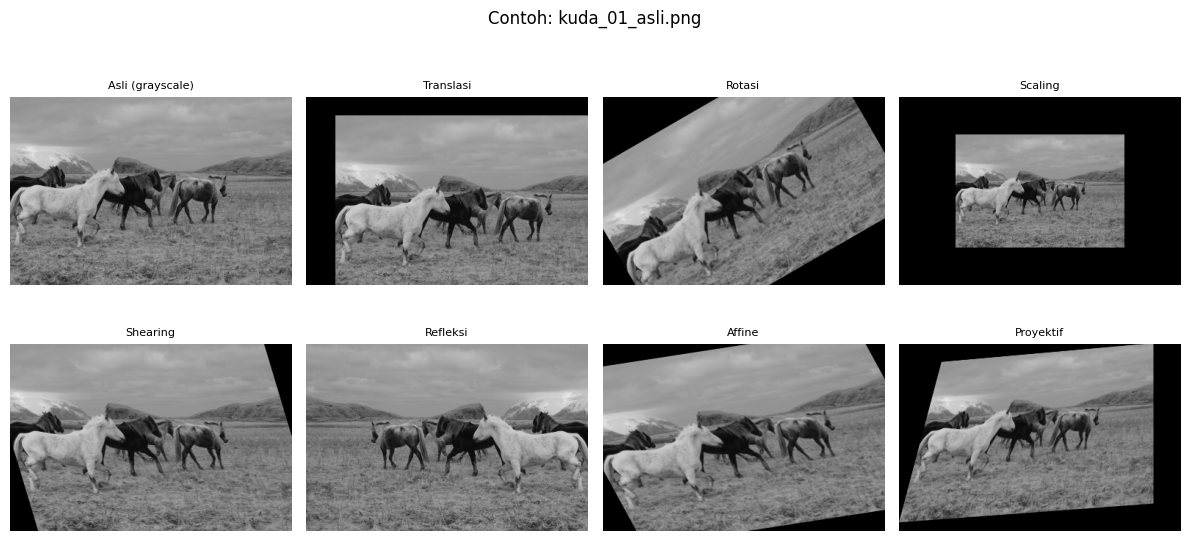

In [6]:
contoh = dataset[0]
hasil_contoh = {k: f(contoh) for k, f in DAFTAR_TRANSFORMASI.items()}
tampilkan([contoh] + list(hasil_contoh.values()),
          ["Asli (grayscale)"] + [k.split("_")[1] for k in hasil_contoh],
          kolom=4, ukuran_sel=3, suptitle=f"Contoh: {nama_file[0]}")

## 7. Proses Seluruh Dataset (≥ 20 Citra)
Setiap citra ditransformasi dengan ketujuh metode dan hasilnya disimpan ke folder `hasil_transformasi/<nama_transformasi>/`.

In [7]:
hasil_semua = {k: [] for k in DAFTAR_TRANSFORMASI}

for nama, citra in zip(nama_file, dataset):
    for kode, fungsi in DAFTAR_TRANSFORMASI.items():
        out = fungsi(citra)
        hasil_semua[kode].append(out)
        folder = os.path.join(FOLDER_HASIL, kode)
        os.makedirs(folder, exist_ok=True)
        cv2.imwrite(os.path.join(folder, nama), out)

print(f"{len(dataset)} citra x {len(DAFTAR_TRANSFORMASI)} transformasi = "
      f"{len(dataset) * len(DAFTAR_TRANSFORMASI)} hasil, tersimpan di: {FOLDER_HASIL}")

20 citra x 7 transformasi = 140 hasil, tersimpan di: /content/hasil_transformasi


## 8. Hasil Seluruh Dataset

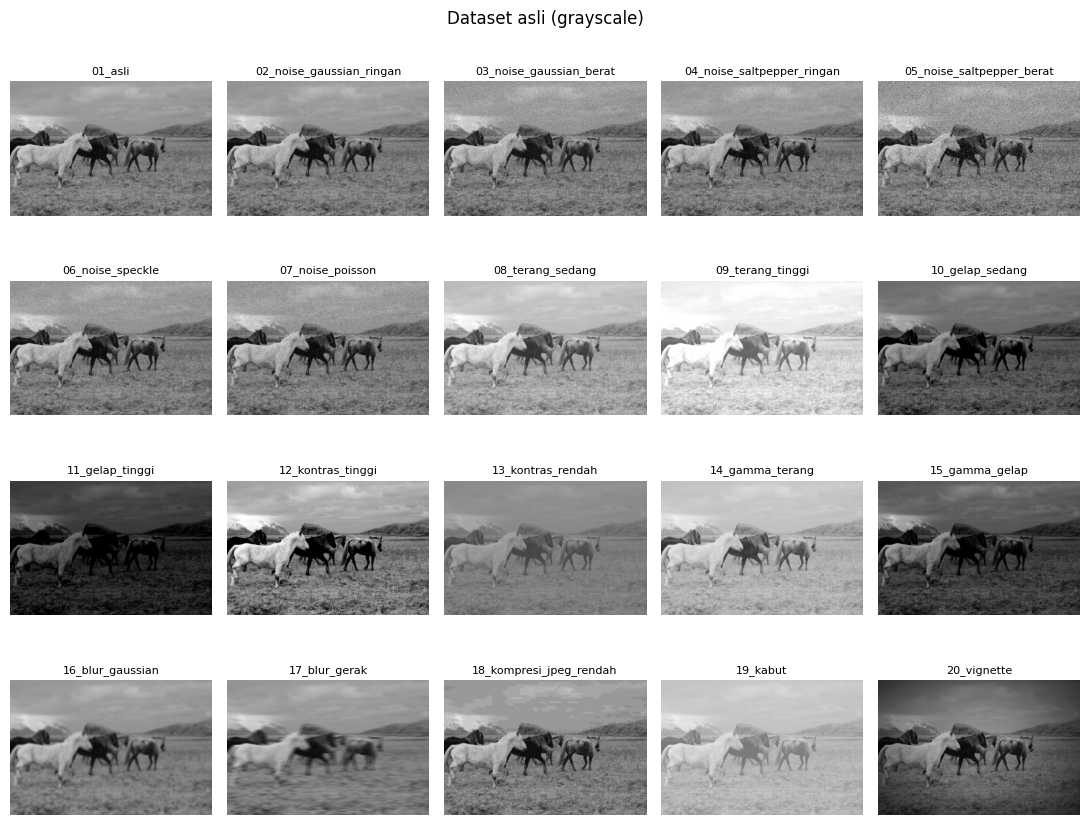

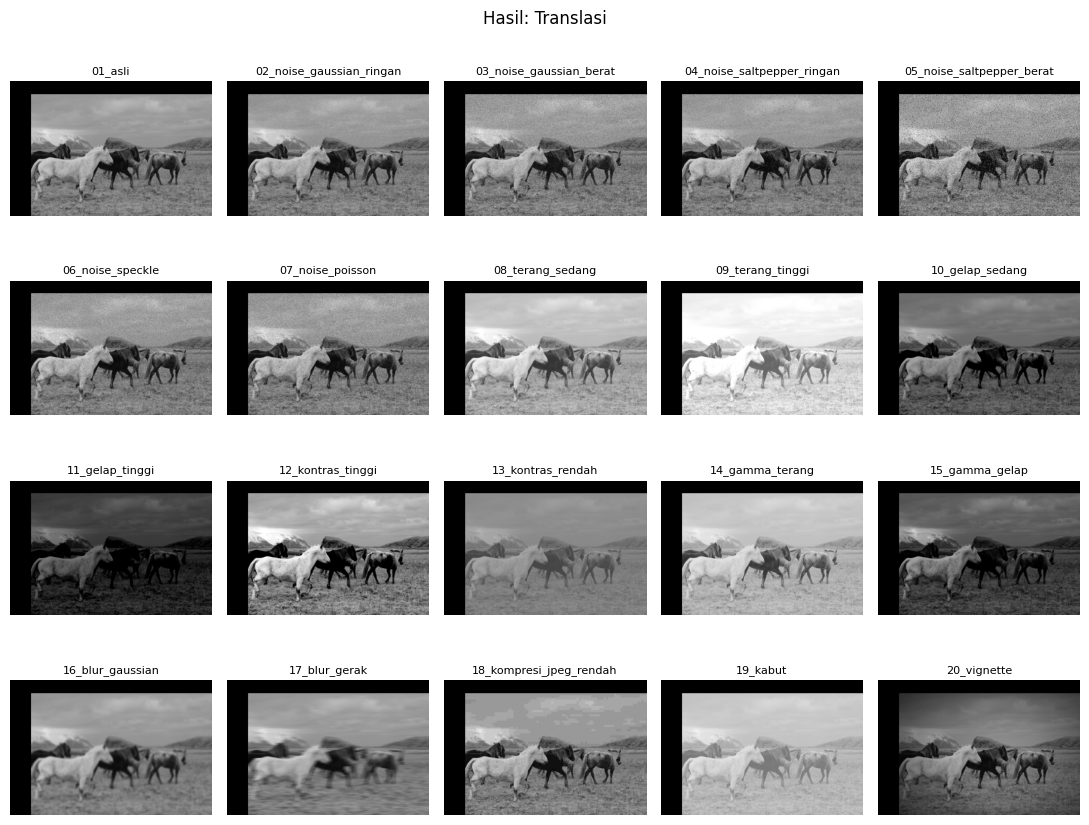

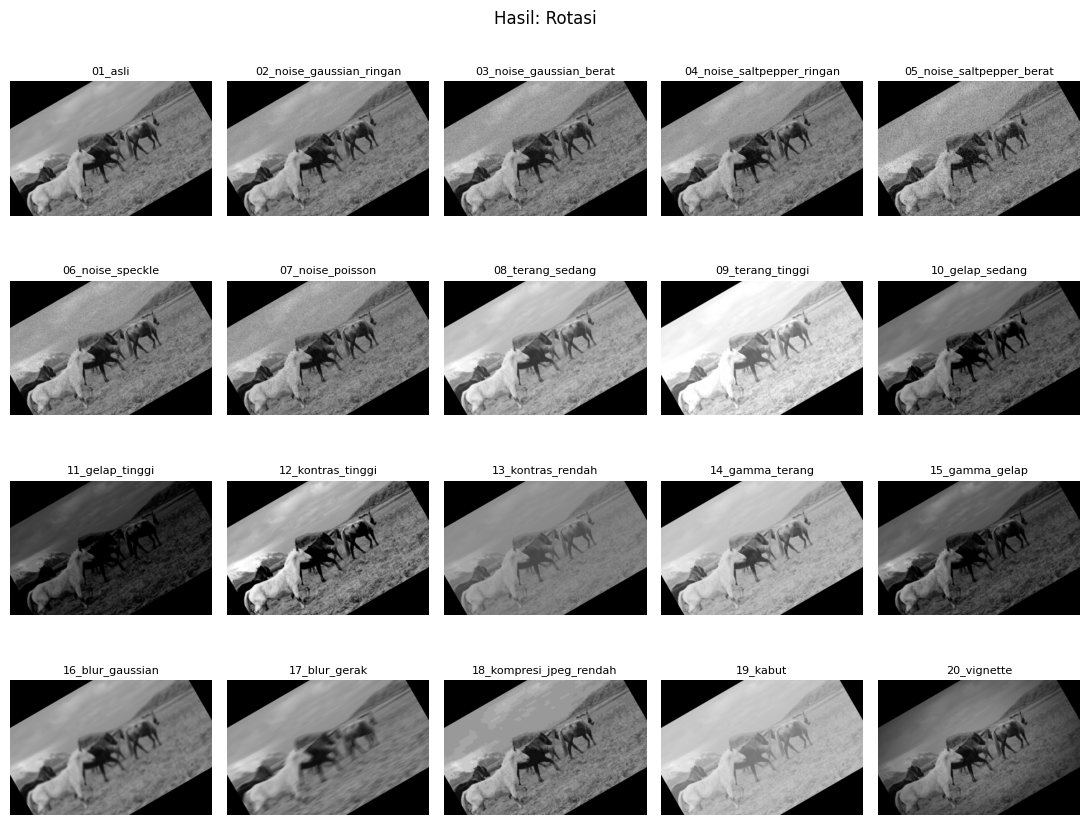

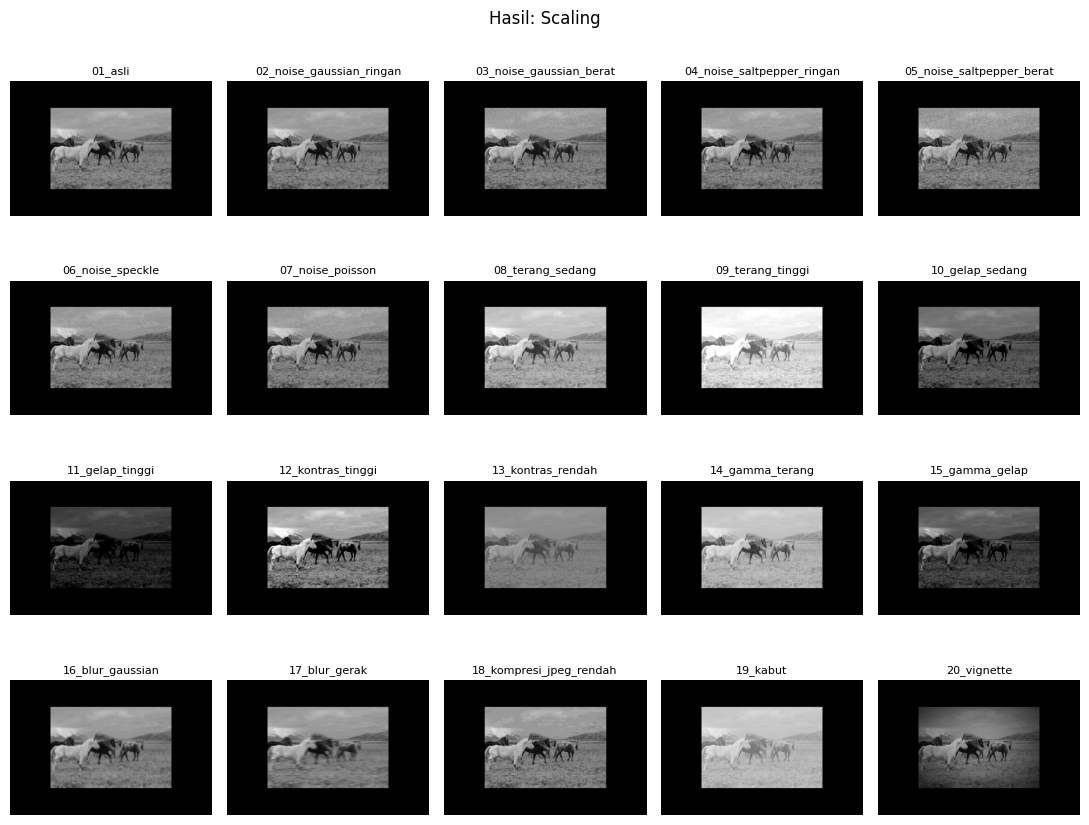

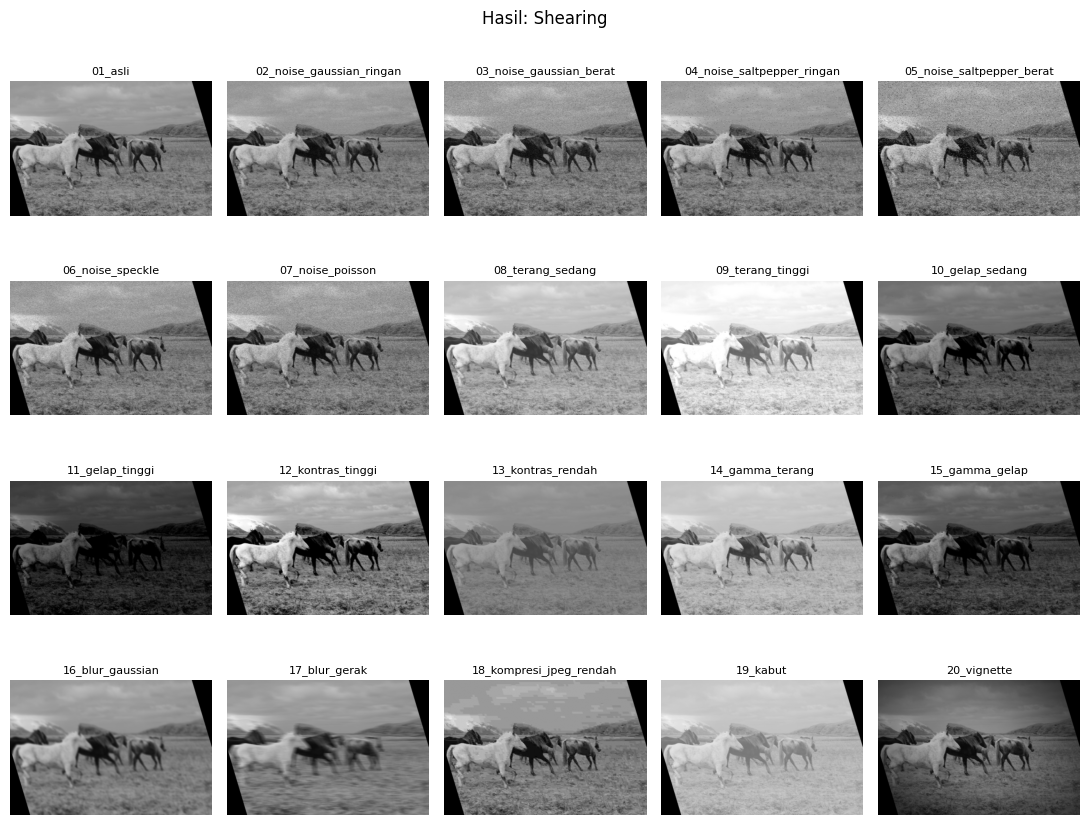

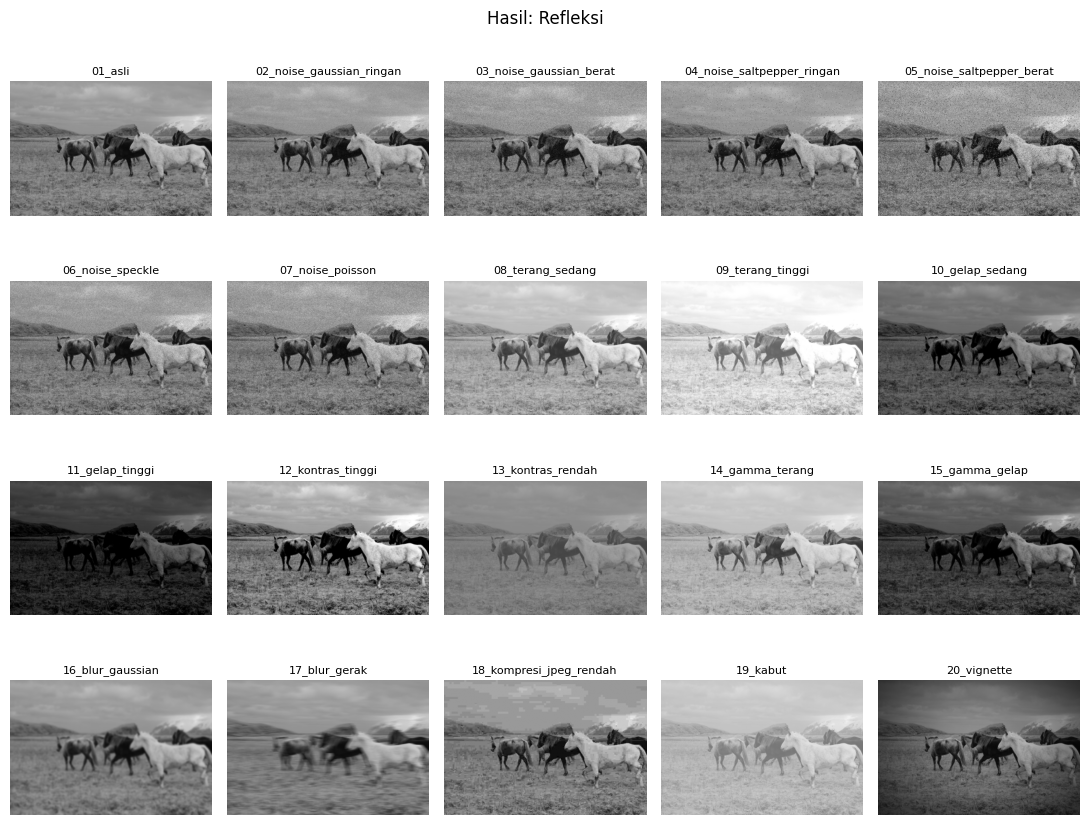

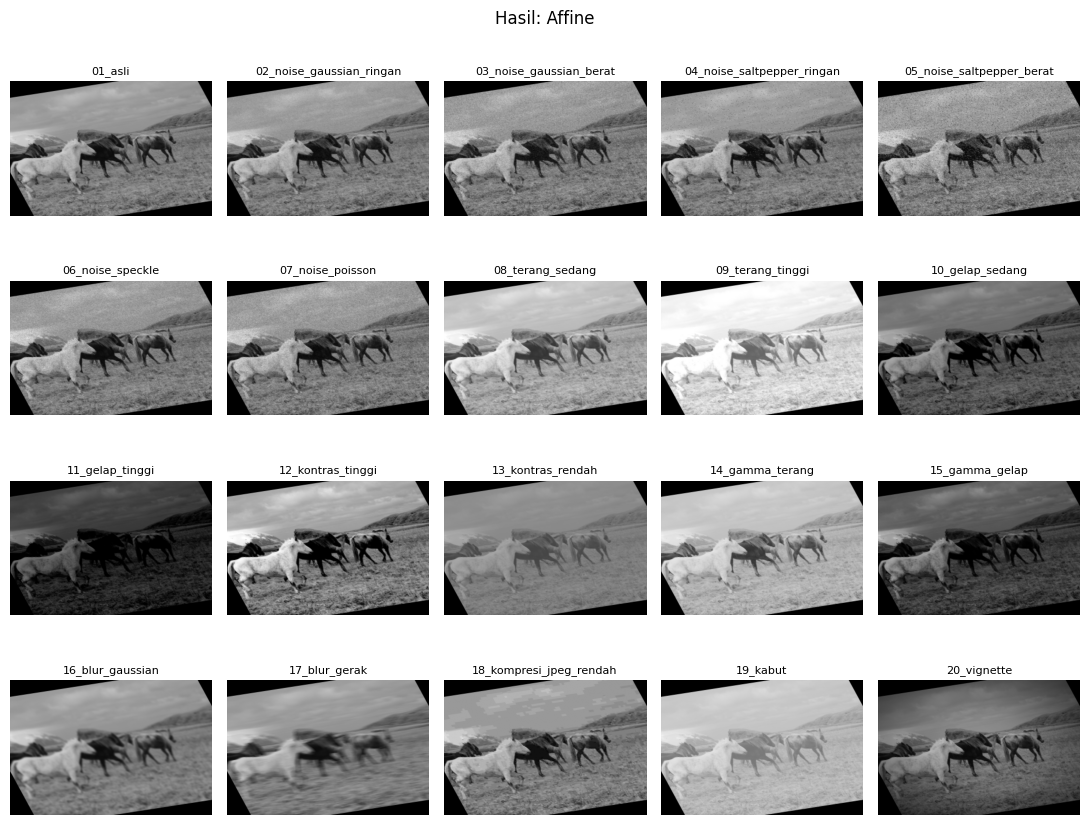

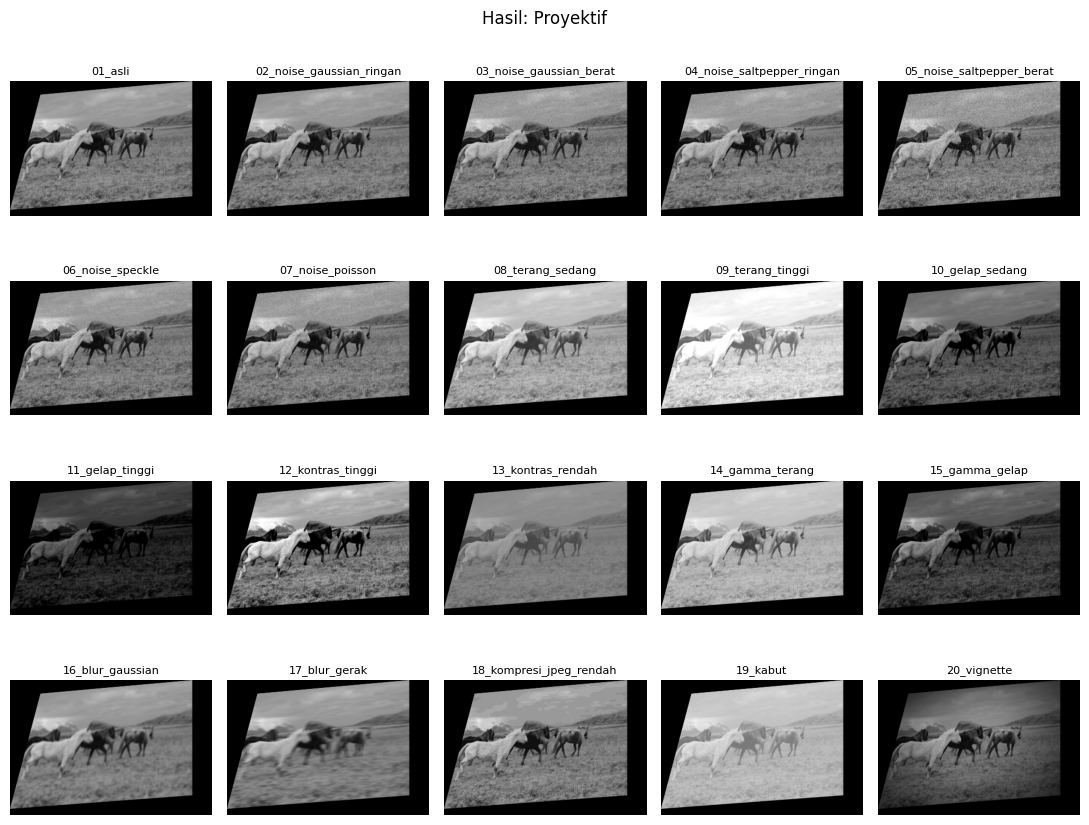

In [8]:
label = [n[5:].rsplit(".", 1)[0] for n in nama_file]   # buang awalan "kuda_" dan ekstensi
tampilkan(dataset, label, suptitle="Dataset asli (grayscale)")
for kode, daftar in hasil_semua.items():
    tampilkan(daftar, label, suptitle=f"Hasil: {kode.split('_')[1]}")

## 9. Ringkasan Matriks Transformasi
| Transformasi | Matriks / Metode | Parameter |
|---|---|---|
| Translasi | `[[1,0,tx],[0,1,ty]]` | tx, ty |
| Rotasi | `[[cosθ, sinθ],[-sinθ, cosθ]]` terhadap pusat | sudut |
| Scaling | `[[sx,0],[0,sy]]` terhadap pusat | sx, sy |
| Shearing | `[[1,shx],[shy,1]]` terhadap pusat | shx, shy |
| Refleksi | `[[-1,0],[0,1]]` / `[[1,0],[0,-1]]` | sumbu |
| Affine | 3 pasang titik → matriks 2×3 | titik asal & tujuan |
| Proyektif | 4 pasang titik → homografi 3×3 | titik asal & tujuan |

**Catatan:** area kosong hasil transformasi diisi hitam (0). Affine mempertahankan kesejajaran garis, sedangkan proyektif tidak (garis sejajar dapat bertemu di titik hilang).